# 使用真实数据，测试 factors/diagnostic_portfolio 模块

In [1]:
from factors.library.momentum import MomentumFactor
from factors.diagnostic_portfolio import DiagnosticPortfolioExperimentRunner
from factors.dataset import ResearchDatasetBuilder
from factors.models import DatasetSpec, UniverseSpec, DataRequirement
from data.config import RolloverConfig, AdjustmentConfig, SamplingConfig, EnvironmentConfig
from data import DataFacade
from factors.preprocess import (
    PreprocessingPipeline, CrossSectionalMissingHandler, RollingTimeSeriesMissingHandler,
    CrossSectionalWinsorizer, RollingTimeseriesWinsorizer, 
)
from factors.diagnostic_portfolio import (
    DiagnosticPortfolioExperimentRunner, 
    DiagnosticPortfolioSpec,
    DiagnosticSignal,
    RebalanceConfig, 
    RiskConfig,
    CostConfig,
    ConstraintConfig
)
from factors.profiles import market_rank_ls, ts_inv_vol_gross_one, ts_inv_vol_target_vol                                   

In [2]:
# 加载研究数据
roll_config = RolloverConfig()
adj_config = AdjustmentConfig()
sample_config = SamplingConfig()
env_config = EnvironmentConfig()
facade_config = (roll_config, adj_config, sample_config, env_config)

facade = DataFacade(*facade_config)

products = facade.rule_query.get_product_universe(return_type='list')
products = [x for x in products if x not in ('L_F', 'PP_F', 'V_F')]

req1 = DataRequirement(source='main_panel', )
data_req = (req1, )

uni_spec = UniverseSpec(min_average_volume=10000)

data_spec = DatasetSpec(facade_config=facade_config,products=tuple(products),
                        data_requirements=data_req, universe=uni_spec)

builder = ResearchDatasetBuilder(spec=data_spec)
dataset = builder.build()

【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\A_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\AD_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\AG_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\AL_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\AO_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\AP_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\AU_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\B_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\BB_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\BC_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持

profile = 'market_rank_ls'

In [3]:
# calculate momentum factor
R = 15
H = 10
momentum = MomentumFactor(lookback=R)
mom_values = momentum.compute(data=dataset.main_panel)

# run experiment
signal = DiagnosticSignal(name=f'momentum_{R}', values=mom_values,source_stage='raw',
                          factor_name=f'momentum_{R}', recipe={})
rebalance_config = RebalanceConfig(interval=H, anchor=None)
constraint_config = ConstraintConfig()
cost_config = CostConfig(rate=3e-5)
spec = DiagnosticPortfolioSpec(name=f'momentum_{R}', harvest_profile=market_rank_ls, 
                               rebalance=rebalance_config, constraint=constraint_config, 
                               cost=cost_config, min_cross_section_size=2,
                               missing_return_policy='default_to_zero_and_warning'
                               )
runner = DiagnosticPortfolioExperimentRunner(signal=signal, dataset=dataset, spec=spec)
result = runner.run()

<Axes: xlabel='timestamp'>

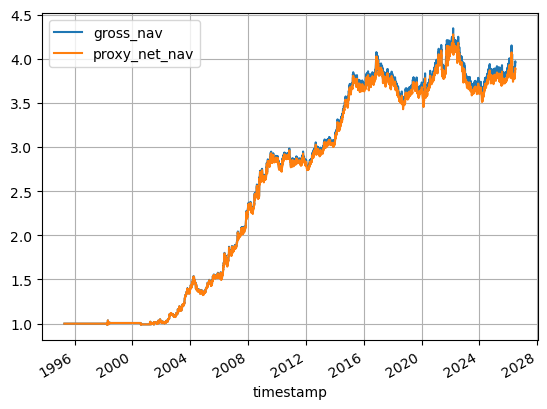

In [4]:
result.nav.plot(grid=True)


profile = 'ts_inv_vol_gross_one'

In [5]:
from factors.preprocess.scale import FittedTimeSeriesZscore
# calculate momentum factor
R = 15
H = 10
vol_R = 15
momentum = MomentumFactor(lookback=R)
mom_values = momentum.compute(data=dataset.main_panel)
mom_values.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
clip_bound = mom_values.quantile(0.99)
print(f'profile = "ts_inv_vol_gross_one", clip_bound is: {clip_bound}')

# run experiment
signal = DiagnosticSignal(name=f'momentum_{R}', values=mom_values,source_stage='raw',
                          factor_name=f'momentum_{R}', recipe={})
rebalance_config = RebalanceConfig(interval=H, anchor=None)
constraint_config = ConstraintConfig()
cost_config = CostConfig(rate=3e-5)
risk_config = RiskConfig(volatility_lookback=vol_R, 
                         volatility_min_periods=2,
                         )
spec = DiagnosticPortfolioSpec(name=f'momentum_{R}', harvest_profile=ts_inv_vol_gross_one, 
                               rebalance=rebalance_config, constraint=constraint_config, 
                               cost=cost_config, risk=risk_config, clip_bound=clip_bound,
                               missing_return_policy='default_to_zero_and_warning'
                               )
runner = DiagnosticPortfolioExperimentRunner(signal=signal, dataset=dataset, spec=spec)
result = runner.run()

profile = "ts_inv_vol_gross_one", clip_bound is: 0.18264088045702276


<Axes: xlabel='timestamp'>

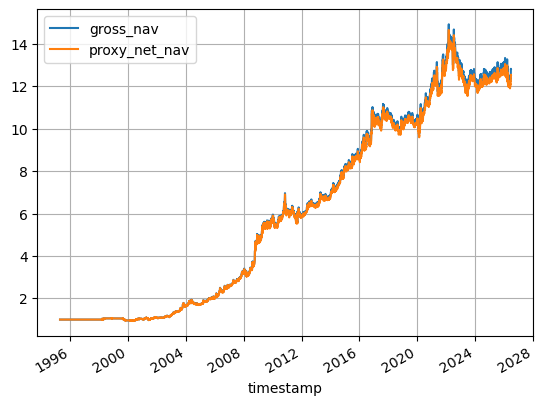

In [6]:

result.nav.plot(grid=True)


In [7]:
result.performance

,total_return,annualized_arithmetic_return,cagr,annualized_volatility,sharpe,max_drawdown,n_periods
return_type,,,,,,,
gross,11.817772,0.090245,0.088369,0.105414,0.856101,-0.211457,7591
proxy_net,11.540153,0.089518,0.087578,0.105414,0.849205,-0.212403,7591


profile = 'ts_inv_vol_target_vol'


profile = "ts_inv_vol_target_vol", clip_bound is: 0.18264088045702276


<Axes: xlabel='timestamp'>

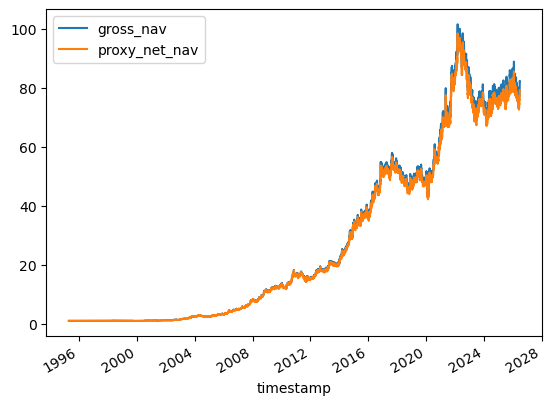

In [10]:
R = 15
H = 10
vol_R = 30
cov_R = 30

momentum = MomentumFactor(lookback=R)
mom_values = momentum.compute(data=dataset.main_panel)
mom_values.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
clip_bound = mom_values.quantile(0.99)
print(f'profile = "ts_inv_vol_target_vol", clip_bound is: {clip_bound}')

# run experiment
signal = DiagnosticSignal(name=f'momentum_{R}', values=mom_values,source_stage='raw',
                          factor_name=f'momentum_{R}', recipe={})
rebalance_config = RebalanceConfig(interval=H, anchor=None)
constraint_config = ConstraintConfig(
    max_gross=2.5, max_product_weight=None, max_volatility_scaler=2.5
)
cost_config = CostConfig(rate=3e-5)
risk_config = RiskConfig(
    volatility_lookback=vol_R, volatility_min_periods=2,
    covariance_lookback=cov_R, covariance_min_periods=5,
    target_volatility=0.15
)
spec = DiagnosticPortfolioSpec(name=f'momentum_{R}', harvest_profile=ts_inv_vol_target_vol, 
                               rebalance=rebalance_config, constraint=constraint_config, 
                               cost=cost_config, risk=risk_config, clip_bound=clip_bound,
                               missing_return_policy='default_to_zero_and_warning'
                               )
runner = DiagnosticPortfolioExperimentRunner(signal=signal, dataset=dataset, spec=spec)
result = runner.run()
result.nav.plot()

             total_return  annualized_arithmetic_return      cagr  annualized_volatility    sharpe  max_drawdown  n_periods
return_type                                                                                                                
gross           81.313825                      0.157810  0.157680               0.150770  1.046693     -0.316352       7591
proxy_net       78.212148                      0.156534  0.156204               0.150766  1.038256     -0.318640       7591


<Axes: xlabel='timestamp'>

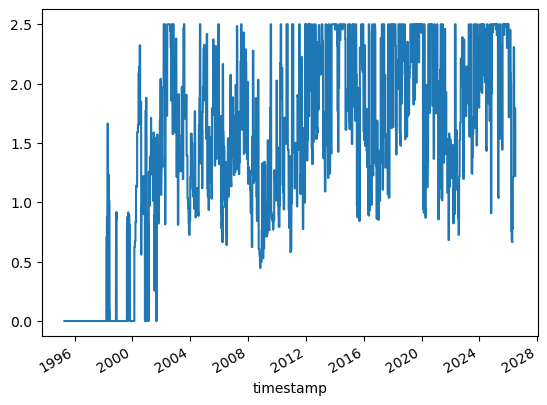

In [20]:
print(result.performance.to_string())
result.exposures['gross_exposure'].plot()